# A. Date KITTI + teacher GMStereo (Colab, GPU)

Fazele 2 și 3 din plan. Rulează o singură dată; rezultatele rămân pe Google Drive.

**Înainte:** urcă folderul `cod/` în `MyDrive/ECA_depth/cod` și alege *Runtime → Change runtime type* → **T4 GPU**, **Runtime version: 2026.07** (același runtime ca la notebook-ul B).

Durată estimată: descărcare ~15 GB din KITTI, apoi teacher-ul (sub 1 s/cadru pe T4). Dacă sesiunea se închide, rulează din nou celulele: scripturile sar peste secvențele deja terminate.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.environ["ECA_ROOT"] = "/content/drive/MyDrive/ECA_depth"   # date și rezultate (persistente)
os.environ["ECA_RAW"] = "/content/kitti_raw"                  # KITTI brut (disc local, temporar)
os.environ["UNIMATCH_DIR"] = "/content/unimatch"
# os.environ["ECA_DEBUG"] = "1"   # decomentează pentru un test rapid pe 2 secvențe mici

COD = "/content/drive/MyDrive/ECA_depth/cod"   # aici ai urcat folderul cod/
%cd {COD}
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
/content/drive/MyDrive/ECA_depth/cod
name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Download teacher-ului (UniMatch).

In [2]:
!git clone -q https://github.com/autonomousvision/unimatch.git /content/unimatch || echo "există deja"
import torch; print("PyTorch", torch.__version__, "| GPU:", torch.cuda.is_available())

PyTorch 2.11.0+cu130 | GPU: True


## 2. Pregătirea datelor (faza 2)
Descarcă fiecare secvență, păstrează doar camerele color (+ LiDAR pentru val/test) și salvează `proc/<secvență>.npz`.

In [3]:
!python 01_pregatire_date.py

  descarc https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_calib.zip
Calibrare: fx=721.54px, baseline=0.5327m, imagine 1242x375
[train] 2011_09_26_drive_0001_sync: există deja, sar peste
[train] 2011_09_26_drive_0005_sync: există deja, sar peste
[train] 2011_09_26_drive_0011_sync: există deja, sar peste
[train] 2011_09_26_drive_0014_sync: există deja, sar peste
[train] 2011_09_26_drive_0015_sync: există deja, sar peste
[train] 2011_09_26_drive_0017_sync: există deja, sar peste
[train] 2011_09_26_drive_0018_sync: există deja, sar peste
[train] 2011_09_26_drive_0035_sync: există deja, sar peste
[train] 2011_09_26_drive_0039_sync: există deja, sar peste
[train] 2011_09_26_drive_0057_sync: există deja, sar peste
[train] 2011_09_26_drive_0060_sync: există deja, sar peste
[train] 2011_09_26_drive_0091_sync: există deja, sar peste
[train] 2011_09_26_drive_0095_sync: există deja, sar peste
[train] 2011_09_26_drive_0104_sync: există deja, sar peste
[val] 2011_09_26_drive_0079

## 3. Verificare vizuală: perechea stereo și adâncimea LiDAR

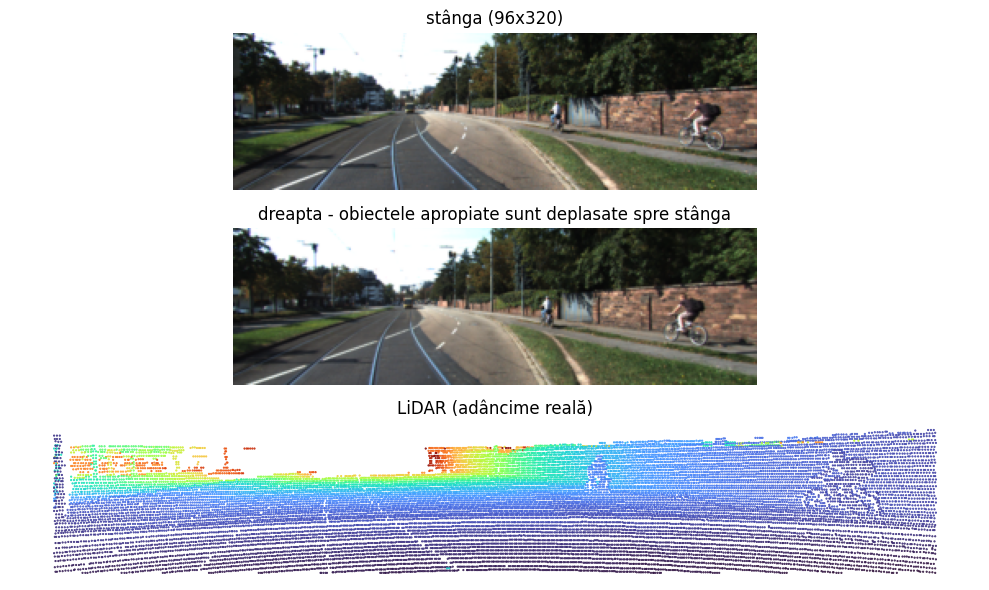

In [4]:
import numpy as np, matplotlib.pyplot as plt, config as C
d = np.load(f"{C.PROC_DIR}/{C.drive_name(C.SPLITS['test'][0])}.npz")
gt = d["gt"][0].astype(float)
ys, xs = np.nonzero(gt)
fig, ax = plt.subplots(3, 1, figsize=(10, 6))
ax[0].imshow(d["left"][0]); ax[0].set_title("stânga (96x320)")
ax[1].imshow(d["right"][0]); ax[1].set_title("dreapta - obiectele apropiate sunt deplasate spre stânga")
ax[2].scatter(xs, ys, c=gt[ys, xs], s=0.3, cmap="turbo"); ax[2].invert_yaxis(); ax[2].set_title("LiDAR (adâncime reală)")
for a in ax: a.axis("off")
plt.tight_layout()

## 4. Teacher (faza 3)
GMStereo, deja ajustat pe KITTI (nu îl reantrenăm). Salvează `proc/<secvență>_teacher_gmstereo_kitti15_04487ebf.npz` cu disparitatea normalizată și masca de încredere.

In [5]:
!python 02_teacher.py

Dispozitiv teacher: cuda
Teacher GMStereo: 7.35 M parametri
2011_09_26_drive_0001_sync: există deja, sar peste
2011_09_26_drive_0005_sync: există deja, sar peste
2011_09_26_drive_0011_sync: există deja, sar peste
2011_09_26_drive_0014_sync: există deja, sar peste
2011_09_26_drive_0015_sync: există deja, sar peste
2011_09_26_drive_0017_sync: există deja, sar peste
2011_09_26_drive_0018_sync: există deja, sar peste
2011_09_26_drive_0035_sync: există deja, sar peste
2011_09_26_drive_0039_sync: lipsesc imagini originale; le descarc din nou
  descarc https://s3.eu-central-1.amazonaws.com/avg-kitti/raw_data/2011_09_26_drive_0039/2011_09_26_drive_0039_sync.zip
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
  50/395  (1.57 s/ca

## 5. Verificare: cât de bun e teacher-ul pe test (față de LiDAR)

In [6]:
!python 04_evaluare.py --modele --split test

I0000 00:00:1793712092.013977   18808 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Evaluare pe test: 381 cadre
| teacher GMStereo (stereo, GPU) | 0.056 | 0.344 | 3.063 | 0.157 | 0.946 | 0.970 | 0.982 |
Tabel salvat: /content/drive/MyDrive/ECA_depth/rezultate_test.md
Figuri salvate în /content/drive/MyDrive/ECA_depth/figuri


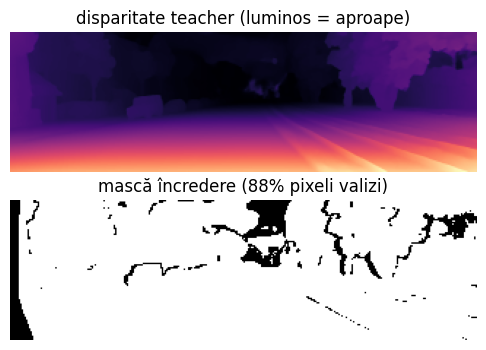

In [7]:
t = np.load(f"{C.PROC_DIR}/{C.drive_name(C.SPLITS['train'][0])}_teacher_gmstereo_kitti15_04487ebf.npz")
fig, ax = plt.subplots(2, 1, figsize=(10, 4))
ax[0].imshow(t["q"][0].astype(float), cmap="magma"); ax[0].set_title("disparitate teacher (luminos = aproape)")
ax[1].imshow(t["mask"][0], cmap="gray"); ax[1].set_title(f"mască încredere ({100*t['mask'].mean():.0f}% pixeli valizi)")
for a in ax: a.axis("off")

## 6. (Opțional) Eliberează spațiu
După ce toate fișierele `_teacher_gmstereo_kitti15_04487ebf.npz` există, KITTI brut nu mai e necesar.

In [8]:
# !rm -rf /content/kitti_raw